# Diffusion image generator

Ce notebook implémente un **Denoising Diffusion Probabilistic Model** (Ho et al., 2020) pour générer des chiffres manuscrits MNIST. Le modèle ajoute progressivement du bruit gaussien à des images (processus **forward**) et apprend à inverser ce processus pour générer de nouvelles images à partir de bruit pur (processus **reverse**).

### Évaluation
Le modèle est évalué avec trois mesures adaptées à un modèle génératif :
  1. **FID** (Fréchet Inception Distance), la métrique standard, aussi utilisée dans l'article DDPM ;
  2. un **classifieur juge** MNIST, qui mesure si les chiffres sont reconnaissables et si les 10 classes sont toutes générées (diversité) ;
  3. un **test de mémorisation** par **KNN**, pour vérifier que le modèle ne recopie pas les images d'entraînement.


- **Session 1 :** entraînement (environ 1 h sur T4). **Session 2 :** génération et évaluation (environ 1 h).
- La **précision mixte (AMP, float16)** accélère les calculs sur GPU sans changer le modèle.

**Référence :** Ho, J., Jain, A., & Abbeel, P. (2020). *Denoising Diffusion Probabilistic Models*. NeurIPS 2020.

## Installation

### Explication
- **torchmetrics** fournit `FrechetInceptionDistance`.
- **torch-fidelity** fournit le réseau InceptionV3 utilisé pour extraire les caractéristiques des images.

In [1]:
!pip install -q torchmetrics torch-fidelity

## Imports

### Objectif
Cette cellule importe les bibliothèques nécessaires pour construire, entraîner, et évaluer un modèle de Denoising Diffusion Probabilistic Model (DDPM) sur le dataset MNIST.

### Explication
- **torch** : Fournit les tenseurs et les outils pour les réseaux de neurones.
- **torch.nn** et **torch.nn.functional** : Définition des couches (convolutions, batch norm, etc.) et fonctions d'activation (ReLU, etc.).
- **torchvision** et **transforms** : Chargement et prétraitement du dataset MNIST.
- **DataLoader** : Création de batches pour l'entraînement et l'évaluation.
- **matplotlib.pyplot** et **numpy** : Visualisation des résultats et calculs numériques.
- **tqdm** : Barre de progression pour les boucles.
- **math** : Fonctions mathématiques (cos, log, etc.).
- **os**, **json**, **time**, **random** : fichiers, sauvegarde des résultats, mesure des temps et reproductibilité.

### Contexte
Ces imports préparent l'environnement pour toutes les étapes du DDPM : modélisation, données, entraînement, génération, et évaluation.

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
import math
import os
import json
import time
import random

## Configuration : reproductibilité et hyperparamètres

### Objectif
Fixer la graine aléatoire, définir les dossiers de sauvegarde et regrouper les hyperparamètres.

### Explication
- **Graine (seed = 42)** : rend l'entraînement et la génération reproductibles.
- **Hyperparamètres** : 50 epochs, batch de 128, learning rate $10^{-4}$.
- **N_GEN = 5000** : nombre d'images générées pour l'évaluation.

In [3]:
SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

try:
    from google.colab import drive
    drive.mount('/content/drive')
    WORK_DIR = '/content/drive/MyDrive/ddpm_mnist'
except ImportError:
    WORK_DIR = './ddpm_mnist_work'
FIG_DIR = os.path.join(WORK_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

CKPT_PATH = os.path.join(WORK_DIR, 'checkpoint.pt')                  # reprise de l'entraînement
MODEL_PATH = os.path.join(WORK_DIR, 'ddpm_mnist_unet.pt')            # poids finaux
LOG_PATH = os.path.join(WORK_DIR, 'training_log.json')
SAMPLES_PATH = os.path.join(WORK_DIR, 'generated_samples.pt')
CLF_PATH = os.path.join(WORK_DIR, 'mnist_classifier.pt')

EPOCHS = 50
BATCH_SIZE = 128
LR = 1e-4
N_GEN = 5000      # images générées pour l'évaluation
GEN_BATCH = 500   # images générées en parallèle

print("Dossier de travail :", WORK_DIR)

Mounted at /content/drive
Dossier de travail : /content/drive/MyDrive/ddpm_mnist


## Configuration du Device

### Objectif
Détecter si un GPU est disponible pour accélérer les calculs, sinon utiliser le CPU.

### Explication
- La ligne `device = torch.device("cuda" if torch.cuda.is_available() else "cpu")` vérifie la disponibilité de CUDA (GPU). Si disponible, `device="cuda"`, sinon `device="cpu"`.

### Contexte
Le DDPM implique des calculs intensifs (convolutions, matrices). Utiliser un GPU (CUDA) accélère significativement l'entraînement et la génération.

La **précision mixte (AMP)** est activée seulement sur GPU : les produits matriciels sont calculés en float16, environ 2 fois plus vite sur un T4.

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
GPU_NAME = torch.cuda.get_device_name(0) if USE_AMP else "CPU"
print("Device :", device, "|", GPU_NAME)

Device : cuda | Tesla T4


## Fonction `betas_for_alpha_bar`

### Objectif
Calculer les paramètres $\beta_t$ (variance du bruit) pour un schedule de diffusion cosinus, qui contrôle l'ajout progressif de bruit.

### Explication
- La fonction prend :
  - `num_diffusion_timesteps` : Nombre de pas $T$.
  - `alpha_bar` : Fonction définissant $\bar{\alpha}_t$, le produit cumulatif des  ${\alpha}_t$.
  - `max_beta` : Valeur maximale de ${\beta}_t$ (par défaut 0.999).
- Boucle sur $i$ de $0$ à $T-1$ :
  - Calcule $t_1 = i/T$ et $t_2 = (i+1)/T$.
  - $\beta_i = \min(1 - \frac{\bar{\alpha}(t_2)}{\bar{\alpha}(t_1)}, \beta_{\max})$.
- Retourne un tenseur de $\beta_t$.

### Formules mathématiques
Dans le DDPM, le schedule cosinus est défini par :
$$
\bar{\alpha}_t = \cos^2\left( \frac{t + s}{T + s} \cdot \frac{\pi}{2} \right), \quad s = 0.008
$$
$$
\beta_t = \min\left(1 - \frac{\bar{\alpha}_{t+1}}{\bar{\alpha}_t}, \beta_{\max}\right)
$$
Le paramètre $s$ évite des $\beta_t$ trop petits au début.

### Contexte
Les $\beta_t$ définissent la quantité de bruit ajouté à chaque timestep dans le processus forward. Le schedule cosinus est préféré au linéaire pour une transition plus douce.

### Remarque
L'article DDPM original utilise un schedule **linéaire** ($\beta_1 = 10^{-4}$ à $\beta_T = 0.02$). Le schedule **cosinus** utilisé ici a été proposé ensuite par Nichol & Dhariwal (2021, *Improved Denoising Diffusion Probabilistic Models*).

In [5]:
# ---------------- Diffusion Schedule ----------------

def betas_for_alpha_bar(num_diffusion_timesteps, alpha_bar, max_beta=0.999):
    betas = []
    for i in range(num_diffusion_timesteps):
        t1 = i / num_diffusion_timesteps
        t2 = (i + 1) / num_diffusion_timesteps
        betas.append(min(1 - alpha_bar(t2) / alpha_bar(t1), max_beta))
    return torch.tensor(betas, dtype=torch.float32)

## Configuration du Schedule de Diffusion

### Objectif
Définir les paramètres du processus de diffusion (($T=1000$), schedule cosinus) et précalculer les tenseurs pour optimiser le sampling.

### Explication
- Définit $T=1000$ (nombre de timesteps).
- Si `schedule_name="linear"`, utilise $\beta_t$ linéaires de 0.0001 à 0.02.
- Sinon (`cosine`), utilise `betas_for_alpha_bar` avec :
  $$
\bar{\alpha}_t = \cos^2\left( \frac{t + 0.008}{1.008} \cdot \frac{\pi}{2} \right)
$$
- Calcule :
  - $\alpha_t = 1 - \beta_t$
  - $\bar{\alpha}_t = \prod_{i=1}^t \alpha_i$
  - $\bar{\alpha}_{t-1}$ (décalé avec padding).
  - $\sqrt{\bar{\alpha}_t}$ , $\sqrt{1 - \bar{\alpha}_t}$ ,$\sqrt{\frac{1}{\alpha_t}}$

  - Variance postérieure : $\tilde{\beta}_t = \beta_t \cdot \frac{1 - \bar{\alpha}_{t-1}}{1 - \bar{\alpha}_t}$.

### Formules mathématiques
- Processus forward :
  $$
x_t = \sqrt{\bar{\alpha}_t} x_0 + \sqrt{1 - \bar{\alpha}_t} \epsilon, \quad \epsilon \sim \mathcal{N}(0, I)
$$
- Variance postérieure :
  $$
\tilde{\beta}_t = \beta_t \cdot \frac{1 - \bar{\alpha}_{t-1}}{1 - \bar{\alpha}_t}
$$

### Contexte
Ces tenseurs précalculés accélèrent les calculs dans les processus forward et reverse en évitant des recalculs à chaque itération.

In [6]:
T = 1000
schedule_name = "cosine"
if schedule_name == "linear":
    beta_start = 0.0001
    beta_end = 0.02
    betas = torch.linspace(beta_start, beta_end, T).to(device)
elif schedule_name == "cosine":
    betas = betas_for_alpha_bar(
        T,
        lambda t: math.cos((t + 0.008) / 1.008 * math.pi / 2) ** 2,
    ).to(device)

alphas = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)
alphas_cumprod_prev = F.pad(alphas_cumprod[:-1], (1, 0), value=1.0)
sqrt_alphas_cumprod = torch.sqrt(alphas_cumprod)
sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - alphas_cumprod)
sqrt_recip_alphas = torch.sqrt(1.0 / alphas)
posterior_variance = betas * (1. - alphas_cumprod_prev) / (1. - alphas_cumprod)

## Fonction `extract`

### Objectif
Extraire des valeurs d'un tenseur précalculé (comme $\bar{\alpha}_t$) pour un batch de timesteps $t$.

### Explication
- Prend :
  - `a` : Tenseur précalculé (e.g., $\bar{\alpha}_t$).
  - `t` : Indices des timesteps.
  - `x_shape` : Forme de l'entrée pour broadcasting.
- Extrait `a[t]` et reshape pour correspondre à la forme de l'entrée (batch_size, 1, 1, ...).

### Formules mathématiques
Aucune formule complexe ; utilisé pour broadcaster des scalaires comme $\sqrt{\bar{\alpha}_t}$ sur des tenseurs d'images.

### Contexte
Simplifie le sampling forward/reverse en appliquant les coefficients à un batch d'images.

In [7]:
def extract(a, t, x_shape):
    batch_size = t.shape[0]
    a = a.to(t.device)
    out = a[t]
    return out.view(batch_size, *((1,) * (len(x_shape) - 1)))

## Fonction `q_sample` (Forward Diffusion)

### Objectif
Ajouter du bruit à une image $x_0$ au timestep $t$ selon le processus forward du DDPM.

### Explication
- Si `noise=None`, génère $\epsilon \sim \mathcal{N}(0, I)$.
- Calcule :
  $$
x_t = \sqrt{\bar{\alpha}_t} x_0 + \sqrt{1 - \bar{\alpha}_t} \epsilon
$$
- Utilise `extract` pour obtenir $\sqrt{\bar{\alpha}_t}$ et $\sqrt{1 - \bar{\alpha}_t}$.

### Formules mathématiques
$$
q(x_t | x_0) = \mathcal{N}(x_t; \sqrt{\bar{\alpha}_t} x_0, (1 - \bar{\alpha}_t) I)
$$
C'est une reparamétrisation pour sampler $x_t$ directement sans itérer tous les timesteps.

### Contexte
Simule le processus forward pour l'entraînement, où le modèle apprend à prédire $\epsilon$ à partir de $x_t$.

In [8]:
# ---------------- Forward Diffusion ----------------
def q_sample(x_start, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x_start)
    sqrt_alphas_cumprod_t = extract(sqrt_alphas_cumprod, t, x_start.shape)
    sqrt_one_minus_alphas_cumprod_t = extract(sqrt_one_minus_alphas_cumprod, t, x_start.shape)
    return sqrt_alphas_cumprod_t * x_start + sqrt_one_minus_alphas_cumprod_t * noise

## Fonction `sinusoidal_time_embedding`

### Objectif
Créer des embeddings positionnels pour les timesteps $t$, inspirés des transformers.

### Explication
- Divise `dim` en deux pour sin et cos.
- Calcule $\sin(t \cdot \text{freqs})$ et $\cos(t \cdot \text{freqs})$, concatène.
- Pad si `dim` impair.

### Formules mathématiques
$$
\begin{cases}
PE(t, 2i) = \sin\left( \frac{t}{10000^{2i/d}} \right), \\
PE(t, 2i+1) = \cos\left( \frac{t}{10000^{2i/d}} \right)
\end{cases}
$$


### Contexte
Permet au UNet de conditionner ses prédictions sur le timestep $t$, essentiel pour le débruitage.

In [9]:
# ---------------- Sinusoidal Time Embedding ----------------
def sinusoidal_time_embedding(timesteps, dim):
    half = dim // 2
    device = timesteps.device
    t = timesteps.float().unsqueeze(1)
    freqs = torch.exp(-math.log(10000) * torch.arange(0, half, device=device).float() / half)
    args = t * freqs.unsqueeze(0)
    emb = torch.cat([torch.sin(args), torch.cos(args)], dim=1)
    if dim % 2 == 1:
        emb = F.pad(emb, (0, 1))
    return emb

## Classe `ResidualBlock`

### Objectif
Définir un bloc résiduel avec conditionnement temporel pour le UNet.

### Explication
- Structure :
  - Conv2d (3x3) + BatchNorm + ReLU.
  - Ajout de l'embedding temporel via une projection linéaire.
  - Conv2d (3x3) + BatchNorm + ReLU.
  - Connexion résiduelle (conv 1x1 si les canaux changent, sinon identité).

### Formules mathématiques
$$
h = \text{ReLU}(\text{BN}(\text{Conv}(x))) + \phi(t), \quad h = \text{ReLU}(\text{BN}(\text{Conv}(h))) + \text{res\_conv}(x)
$$
où $\phi(t)$ est l'embedding temporel projeté.

### Contexte
Inspiré des ResNets, ce bloc facilite l'entraînement profond et intègre le conditionnement sur $t$.

In [10]:
# ---------------- UNet Components ----------------
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_embed_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.time_proj = nn.Linear(time_embed_dim, out_channels)
        self.res_conv = nn.Conv2d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()

    def forward(self, x, t_emb):
        h = F.relu(self.bn1(self.conv1(x)))
        h = h + self.time_proj(t_emb).unsqueeze(-1).unsqueeze(-1)
        h = F.relu(self.bn2(self.conv2(h)))
        return h + self.res_conv(x)

## Classe `SelfAttention`

### Objectif
Ajouter un mécanisme de self-attention au bottleneck du UNet pour capturer des dépendances globales.

### Explication
- Projection QKV via Conv2d 1x1
- Reshape pour attention : [B, C, H, W] → [B, H*W, C].
- Attention multi-head : $Q @ K^T, softmax, @ V$
- Projection finale + résidu.

### Formules mathématiques
$$
\text{Attention}(Q, K, V) = softmax\left( \frac{Q K^T}{\sqrt{d_k}} \right) V, \quad d_k = \text{head\_dim}
$$

### Contexte
Améliore la qualité des images générées en captant des relations spatiales globales.

In [11]:
class SelfAttention(nn.Module):
    def __init__(self, channels, num_heads=8):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = channels // num_heads
        assert self.head_dim * num_heads == channels, f"Channels ({channels}) must be divisible by num_heads ({num_heads})"
        self.qkv = nn.Conv2d(channels, channels * 3, 1)
        self.proj = nn.Conv2d(channels, channels, 1)
        self.scale = self.head_dim ** -0.5

    def forward(self, x):
        B, C, H, W = x.shape
        # QKV projection
        qkv = self.qkv(x).reshape(B, 3 * C, H * W).permute(0, 2, 1)  # [B, H*W, 3*C]
        qkv = qkv.view(B, H * W, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)  # [3, B, num_heads, H*W, head_dim]
        q, k, v = qkv[0], qkv[1], qkv[2]  # [B, num_heads, H*W, head_dim]
        # Attention
        attn = (q @ k.transpose(-2, -1)) * self.scale  # [B, num_heads, H*W, H*W]
        attn = attn.softmax(dim=-1)
        out = (attn @ v).transpose(2, 3).reshape(B, H * W, C).view(B, C, H, W)  # [B, C, H, W]
        return self.proj(out) + x

## Classe `UNet`

### Objectif
Définir le modèle principal : un UNet conditionné sur $t$ pour prédire le bruit $\epsilon$.

### Explication
- **Time MLP** : Projette l'embedding temporel via Linear + SiLU + Linear.
- **Encoder** : ResidualBlock (1→128), MaxPool, ResidualBlock (128→256), MaxPool, ResidualBlock (256→512).
- **Bottleneck** : ResidualBlock + SelfAttention.
- **Decoder** : Up-conv + concaténation des skip connections + ResidualBlock.
- **Output** : Conv2d pour prédire le bruit (même forme que l'entrée).

### Formules mathématiques
Le UNet approxime :
$$
\epsilon_\theta(x_t, t)
$$
Loss d'entraînement :
$$
\mathbb{E}_{x_0, t, \epsilon} \left[ \| \epsilon - \epsilon_\theta(\sqrt{\bar{\alpha}_t} x_0 + \sqrt{1 - \bar{\alpha}_t} \epsilon, t) \|^2 \right]
$$

### Contexte
Cœur du DDPM ; prédit le bruit pour débruiter itérativement les images.

In [12]:
class UNet(nn.Module):
    def __init__(self, in_channels=1, model_channels=128, time_embed_dim=256):
        super().__init__()
        self.model_channels = model_channels
        self.time_embed_dim = time_embed_dim
        self.time_mlp = nn.Sequential(
            nn.Linear(time_embed_dim, time_embed_dim * 4),
            nn.SiLU(),
            nn.Linear(time_embed_dim * 4, time_embed_dim)
        )
        # Encoder
        self.down1 = ResidualBlock(in_channels, model_channels, time_embed_dim)
        self.pool1 = nn.MaxPool2d(2)
        self.down2 = ResidualBlock(model_channels, model_channels * 2, time_embed_dim)
        self.pool2 = nn.MaxPool2d(2)
        self.down3 = ResidualBlock(model_channels * 2, model_channels * 4, time_embed_dim)
        # Bottleneck
        self.bottleneck = ResidualBlock(model_channels * 4, model_channels * 4, time_embed_dim)
        self.attn = SelfAttention(model_channels * 4, num_heads=8)
        # Decoder
        self.up3 = nn.ConvTranspose2d(model_channels * 4, model_channels * 2, 4, stride=2, padding=1)
        self.upconv3 = ResidualBlock(model_channels * 4, model_channels * 2, time_embed_dim)
        self.up4 = nn.ConvTranspose2d(model_channels * 2, model_channels, 4, stride=2, padding=1)
        self.upconv4 = ResidualBlock(model_channels * 2, model_channels, time_embed_dim)
        self.out = nn.Conv2d(model_channels, in_channels, 3, padding=1)

    def forward(self, x, t):
        t_emb = sinusoidal_time_embedding(t, self.time_embed_dim)
        t_emb = self.time_mlp(t_emb)
        x1 = self.down1(x, t_emb)
        x2 = self.down2(self.pool1(x1), t_emb)
        x3 = self.down3(self.pool2(x2), t_emb)
        x_b = self.bottleneck(x3, t_emb)
        x_b = self.attn(x_b)
        up3 = self.up3(x_b)
        cat3 = torch.cat([up3, x2], dim=1)
        x = self.upconv3(cat3, t_emb)
        up4 = self.up4(x)
        cat4 = torch.cat([up4, x1], dim=1)
        x = self.upconv4(cat4, t_emb)
        return self.out(x)

## Fonction `train_model`

### Objectif
Entraîner le UNet sur le dataset MNIST.

### Explication
- Optimiseur : AdamW avec learning rate $10^{-4}$ et weight decay.
- Scheduler : CosineAnnealingLR pour ajuster le learning rate.
- Boucle sur epochs :
  - Pour chaque batch :
    - Sample $t$ aléatoire.
    - Ajoute du bruit via `q_sample`.
    - Prédit le bruit avec le UNet.
    - Calcule MSE loss entre bruit prédit et réel.
    - Backprop + update.

### Formules mathématiques
$$
L = \mathbb{E}_{x_0, t, \epsilon} \left[ \| \epsilon - \epsilon_\theta(x_t, t) \|^2 \right]
$$

### Contexte
Entraîne le modèle à prédire le bruit ajouté pour inverser le processus forward.

### Ajouts techniques (sans changer l'apprentissage)
- **Précision mixte (AMP)** : le U-Net calcule en float16 sous `autocast`, et le `GradScaler` évite que les petits gradients deviennent nuls.
- **Checkpoint toutes les 5 epochs** sur Drive (modèle, optimiseur, scheduler, loss). En cas de déconnexion, l'entraînement reprend à la dernière sauvegarde.
- **Temps mesuré** à chaque epoch, pour documenter le coût réel.
- La courbe de loss est tracée plus bas, à partir de l'historique sauvegardé.

In [13]:
# ---------------- Training ----------------
def train_model(model, dataloader, epochs=EPOCHS, lr=LR, ckpt_path=CKPT_PATH, ckpt_every=5):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    losses, start_epoch, train_time = [], 0, 0.0

    # Reprise après une déconnexion
    if os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location=device)
        model.load_state_dict(ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        scheduler.load_state_dict(ckpt["scheduler"])
        scaler.load_state_dict(ckpt["scaler"])
        losses, start_epoch, train_time = ckpt["losses"], ckpt["epoch"], ckpt["train_time"]
        print(f"Reprise de l'entraînement à l'epoch {start_epoch + 1}")

    model.train()
    for epoch in range(start_epoch, epochs):
        t0 = time.time()
        epoch_loss = 0.0
        for batch, _ in tqdm(dataloader, desc=f"Epoch {epoch+1}/{epochs}"):
            batch = batch.to(device, non_blocking=True)
            t = torch.randint(0, T, (batch.shape[0],), device=device)
            noise = torch.randn_like(batch)
            x_noisy = q_sample(batch, t, noise)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                predicted_noise = model(x_noisy, t)
            loss = F.mse_loss(predicted_noise.float(), noise)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            epoch_loss += loss.item()
        scheduler.step()
        epoch_time = time.time() - t0
        train_time += epoch_time
        losses.append(epoch_loss / len(dataloader))
        print(f"Epoch {epoch+1}/{epochs}, Loss: {losses[-1]:.4f}, temps: {epoch_time:.0f} s")

        if (epoch + 1) % ckpt_every == 0 or epoch + 1 == epochs:
            torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                        "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                        "epoch": epoch + 1, "losses": losses, "train_time": train_time}, ckpt_path)
    return losses, train_time

## Fonction `p_sample` (Reverse Diffusion)

### Objectif
Effectuer un pas de débruitage dans le processus reverse.

### Explication
- Calcule la moyenne du posterior avec $\epsilon_\theta(x_t, t)$.
- Ajoute du bruit si $t > 0$ en utilisant la variance postérieure.

### Formules mathématiques
$$
\mu_t = \frac{1}{\sqrt{\alpha_t}} \left( x_t - \frac{\beta_t}{\sqrt{1 - \bar{\alpha}_t}} \epsilon_\theta(x_t, t) \right)
$$
$$
x_{t-1} = \mu_t + \sqrt{\tilde{\beta}_t} z, \quad z \sim \mathcal{N}(0, I)
$$

### Contexte
Inverse le processus forward pour générer $x_{t-1}$ à partir de $x_t$.

En précision mixte, le U-Net calcule en float16 ; sa sortie est reconvertie en float32 avant la mise à jour de $x_t$, pour garder des calculs précis sur 1 000 pas.

In [14]:
# ---------------- Reverse Diffusion ----------------
@torch.no_grad()
def p_sample(model, x, t, t_index):
    betas_t = extract(betas, t, x.shape)
    sqrt_one_minus_alphas_cumprod_t = extract(sqrt_one_minus_alphas_cumprod, t, x.shape)
    sqrt_recip_alphas_t = extract(sqrt_recip_alphas, t, x.shape)
    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
        eps = model(x, t)
    eps = eps.float()
    model_mean = sqrt_recip_alphas_t * (
        x - (betas_t / sqrt_one_minus_alphas_cumprod_t) * eps
    )
    if t_index == 0:
        return model_mean
    posterior_variance_t = extract(posterior_variance, t, x.shape)
    noise = torch.randn_like(x)
    return model_mean + torch.sqrt(posterior_variance_t) * noise

## Fonction `generate_with_steps`

### Objectif
Générer des images en itérant `p_sample`, avec option de sauvegarder les étapes intermédiaires.

### Explication
- Part de $x_T \sim \mathcal{N}(0, I)$.
- Itère de $t=T-1$ à $0$ en appelant `p_sample`.
- Sauvegarde les images à intervalles réguliers si `show_steps=True`.

### Formules mathématiques
Approximation de $q(x_{t-1}|x_t, x_0) \approx p_\theta(x_{t-1}|x_t)$.

### Contexte
Génère des images complètes à partir de bruit pur, avec visualisation des étapes de débruitage.

In [15]:
# ---------------- Generation with Visualization Steps ----------------
@torch.no_grad()
def generate_with_steps(model, n=8, show_steps=True, step_interval=100):
    model.eval()
    x = torch.randn((n, 1, 28, 28), device=device)
    steps_images = [x.cpu()]
    for i in reversed(range(T)):
        t = torch.full((n,), i, device=device, dtype=torch.long)
        x = p_sample(model, x, t, i)
        if show_steps and (i % step_interval == 0 or i == 0):
            steps_images.append(x.clamp(-1, 1).cpu())
    return x.clamp(-1, 1), steps_images

## Chargement du Dataset

### Objectif
Charger et prétraiter le dataset MNIST pour l'entraînement et l'évaluation.

### Explication
- **Transform** : Convertit en tenseur et normalise dans $[-1, 1]$ avec $mean=0.5$, $std=0.5$.
- **DataLoaders** : Crée des itérateurs pour train (batch_size=128, shuffle=True) et test (shuffle=False).

### Formules mathématiques
Normalisation : $(x - 0.5)/0.5 \rightarrow [-1, 1]$, pour aligner avec le bruit $\mathcal{N}(0, I)$.

### Contexte
Prépare les données pour l'entraînement et l'évaluation du modèle.

Les images brutes (entiers de 0 à 255) sont aussi gardées : elles servent de référence pour le FID et le test de mémorisation, au même format que les images générées.

In [16]:
# ---------------- Dataset ----------------
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])
train_dataset = torchvision.datasets.MNIST(root="./data", train=True, transform=transform, download=True)
test_dataset = torchvision.datasets.MNIST(root="./data", train=False, transform=transform, download=True)
train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)

# Images brutes uint8 [N, 1, 28, 28]
train_u8 = train_dataset.data.unsqueeze(1)
test_u8 = test_dataset.data.unsqueeze(1)
print("Train :", tuple(train_u8.shape), "| Test :", tuple(test_u8.shape))

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 493kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.59MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.50MB/s]

Train : (60000, 1, 28, 28) | Test : (10000, 1, 28, 28)


## Entraînement ou chargement du modèle

### Objectif
Créer le U-Net, puis l'entraîner ou charger des poids existants.

### Explication
- Si `ddpm_mnist_unet.pt` existe sur Drive, le modèle est déjà entraîné : on le charge.
- Sinon : entraînement de 50 epochs, avec reprise automatique si un checkpoint existe.

Le nombre de paramètres et le temps d'entraînement sont enregistrés dans `training_log.json`.

In [17]:
model = UNet(in_channels=1, model_channels=128, time_embed_dim=256).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"Paramètres du U-Net : {n_params / 1e6:.1f} M")

if os.path.exists(MODEL_PATH):
    model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
    log = json.load(open(LOG_PATH))
    print("Modèle entraîné chargé depuis Drive")
else:
    print("Entraînement du modèle...")
    losses, train_time = train_model(model, train_dataloader)
    torch.save(model.state_dict(), MODEL_PATH)
    log = {"epochs": EPOCHS, "batch_size": BATCH_SIZE,
           "lr": LR, "seed": SEED, "amp": USE_AMP, "gpu": GPU_NAME, "losses": losses,
           "train_time_min": round(train_time / 60, 1),
           "sec_per_epoch": round(train_time / EPOCHS, 1)}
    json.dump(log, open(LOG_PATH, "w"), indent=2)
    print(f"Entraînement terminé en {train_time / 60:.0f} min")

log["n_params_M"] = round(n_params / 1e6, 2)
model.eval();

Paramètres du U-Net : 16.5 M
Entraînement du modèle...


Epoch 1/50: 100%|██████████| 469/469 [00:54<00:00,  8.54it/s]


Epoch 1/50, Loss: 0.1009, temps: 55 s


Epoch 2/50: 100%|██████████| 469/469 [00:53<00:00,  8.76it/s]


Epoch 2/50, Loss: 0.0625, temps: 54 s


Epoch 3/50: 100%|██████████| 469/469 [00:55<00:00,  8.48it/s]


... (91 outputs left out)

Epoch 49/50: 100%|██████████| 469/469 [00:58<00:00,  7.95it/s]


Epoch 49/50, Loss: 0.0366, temps: 59 s


Epoch 50/50: 100%|██████████| 469/469 [00:58<00:00,  7.98it/s]


Epoch 50/50, Loss: 0.0368, temps: 59 s
Entraînement terminé en 49 min


## Courbe de loss

### Objectif
Vérifier la convergence de l'entraînement.

### Explication
La loss est l'erreur quadratique moyenne entre le bruit réel $\epsilon$ et le bruit prédit $\epsilon_\theta(x_t, t)$, moyennée sur chaque epoch. Elle ne descend pas vers 0 : aux grands $t$, l'image est presque du bruit pur et le bruit ajouté est en partie imprévisible.

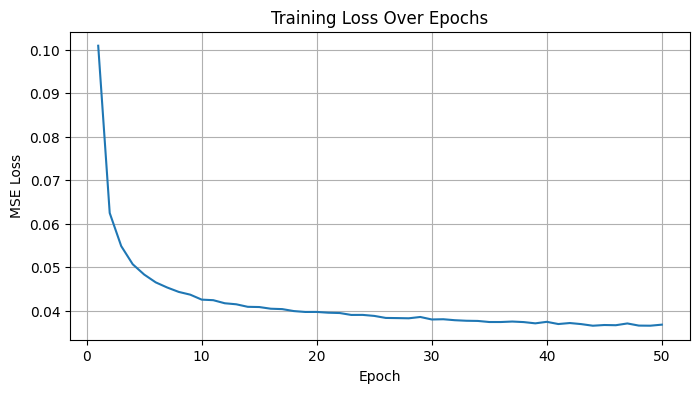

Loss finale : 0.0368


In [18]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(log["losses"]) + 1), log["losses"])
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Training Loss Over Epochs')
plt.grid(True)
plt.savefig(os.path.join(FIG_DIR, 'training_loss.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"Loss finale : {log['losses'][-1]:.4f}")

## Fonction `visualize_steps`

### Objectif
Visualiser les étapes intermédiaires du processus de débruitage.

### Explication
- Affiche une grille d'images pour chaque étape sauvegardée.
- Étiquettes avec le timestep $t$.

### Formules mathématiques
Aucune ; visualisation du processus reverse.

### Contexte
Montre comment le bruit initial devient progressivement une image cohérente.

Les graduations et les bords des images sont masqués un par un (au lieu de `axis('off')`), pour garder l'étiquette $t$ visible au début de chaque ligne.

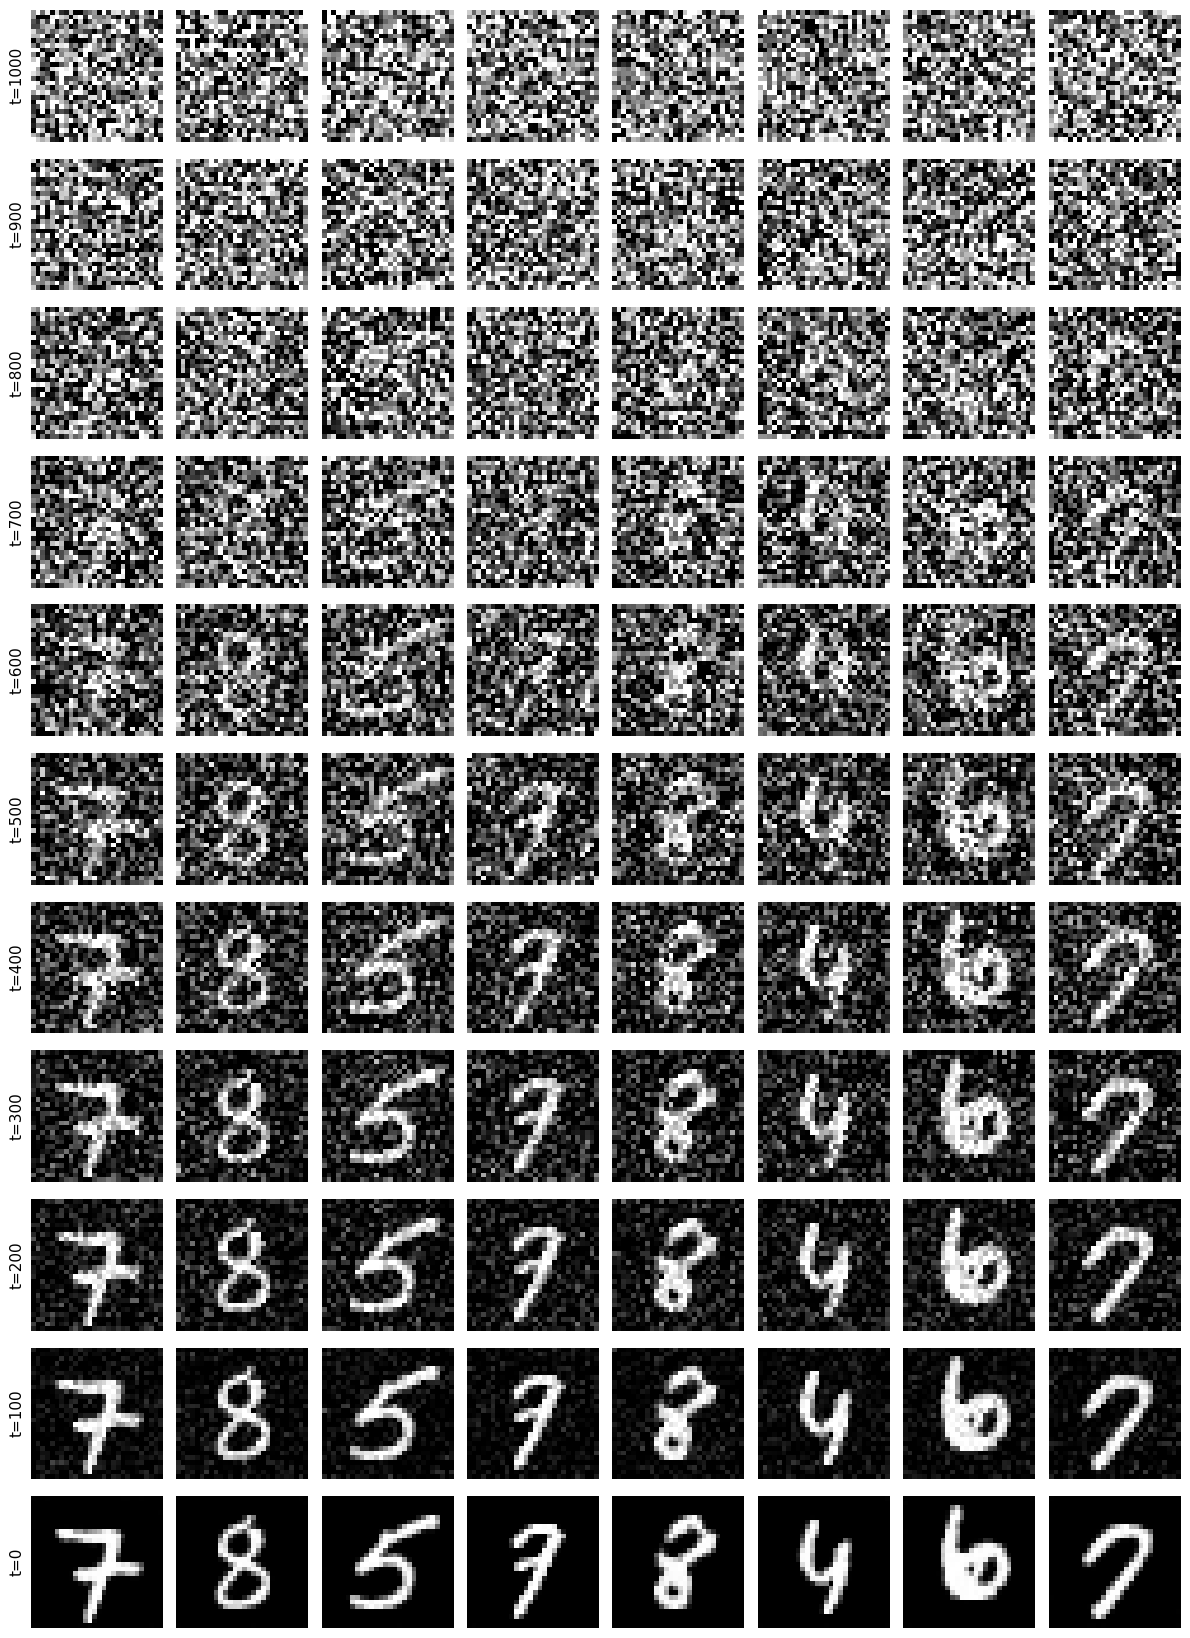

In [19]:
# ---------------- Visualization of Denoising Steps ----------------
def visualize_steps(steps_images, step_interval=100):
    n_steps = len(steps_images)
    n_samples = steps_images[0].shape[0]
    step_times = [T] + [i for i in reversed(range(T)) if i % step_interval == 0]
    fig, axes = plt.subplots(n_steps, n_samples, figsize=(n_samples * 1.5, n_steps * 1.5))
    for i, (step_img, step_t) in enumerate(zip(steps_images, step_times)):
        for j in range(n_samples):
            ax = axes[i, j]
            ax.imshow((step_img[j, 0].clamp(-1, 1) + 1) / 2, cmap='gray', vmin=0, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
        axes[i, 0].set_ylabel(f"t={step_t}", fontsize=11)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, 'denoising_steps.png'), dpi=150, bbox_inches='tight')
    plt.show()

set_seed(SEED)
final_images, steps_images = generate_with_steps(model, n=8, show_steps=True, step_interval=100)
visualize_steps(steps_images)

# Évaluation du modèle génératif

## Pourquoi ne pas utiliser le SSIM ou le PSNR

Un modèle génératif s'évalue sur la **distribution** des images produites :
- **Qualité :** les images ressemblent-elles à de vrais chiffres ?
- **Diversité :** le modèle produit-il toutes les classes, ou toujours les mêmes (*mode collapse*) ?
- **Généralisation :** crée-t-il de nouvelles images, ou recopie-t-il le jeu d'entraînement ?

Les trois sections suivantes répondent à ces trois questions.

## Génération de 5 000 images

### Objectif
Produire l'échantillon sur lequel portent toutes les mesures.

### Explication
- 10 lots de 500 images, chacun avec sa propre graine : la génération est reproductible.
- Chaque image suit les $T = 1000$ pas du processus reverse, comme dans l'article.
- Les images sont converties en entiers de 0 à 255, le même format que MNIST, puis sauvegardées après **chaque lot**.

### Coût
C'est l'étape la plus longue de l'évaluation : 5 000 × 1 000 = 5 millions de passages dans le U-Net.

In [20]:
@torch.no_grad()
def generate_samples(model, n_total=N_GEN, batch_size=GEN_BATCH, path=SAMPLES_PATH):
    state = torch.load(path) if os.path.exists(path) else {"chunks": [], "seconds": 0.0}
    n_batches = math.ceil(n_total / batch_size)
    for b in range(len(state["chunks"]), n_batches):
        torch.manual_seed(SEED + 1 + b)
        n = min(batch_size, n_total - b * batch_size)
        t0 = time.time()
        x, _ = generate_with_steps(model, n=n, show_steps=False)
        state["chunks"].append(((x + 1) * 127.5).round().clamp(0, 255).to(torch.uint8).cpu())
        state["seconds"] += time.time() - t0
        torch.save(state, path)
        print(f"Lot {b + 1}/{n_batches} : {time.time() - t0:.0f} s")
    samples = torch.cat(state["chunks"])[:n_total]
    return samples, state["seconds"]

gen_u8, gen_seconds = generate_samples(model)
print(f"{len(gen_u8)} images générées | {gen_seconds / 60:.1f} min "
      f"| {1000 * gen_seconds / len(gen_u8):.0f} ms par image")

Lot 1/10 : 169 s
Lot 2/10 : 168 s
Lot 3/10 : 168 s
Lot 4/10 : 169 s
Lot 5/10 : 168 s
Lot 6/10 : 169 s
Lot 7/10 : 169 s
Lot 8/10 : 169 s
Lot 9/10 : 169 s
Lot 10/10 : 169 s
5000 images générées | 28.1 min | 337 ms par image


## Grille de 100 échantillons

### Objectif
Montrer un échantillon représentatif, **sans sélection** : ce sont les 100 premières images générées.

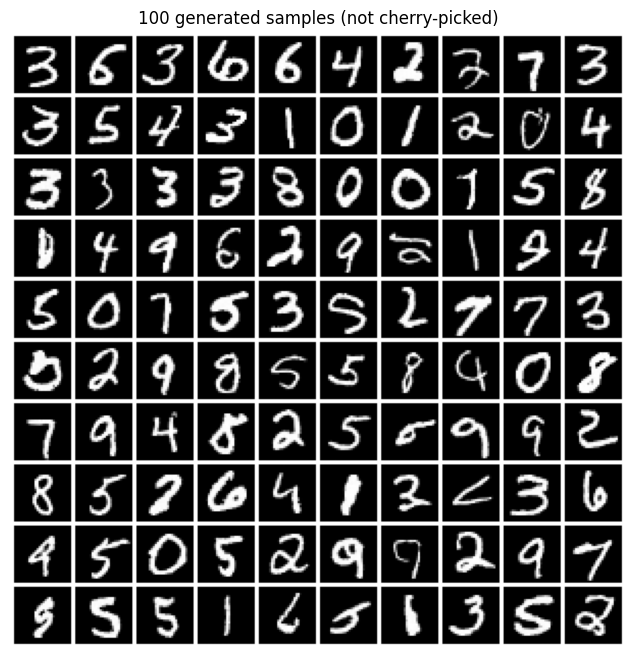

In [21]:
grid = torchvision.utils.make_grid(gen_u8[:100].float() / 255, nrow=10, padding=2, pad_value=1.0)
plt.figure(figsize=(8, 8))
plt.imshow(grid[0], cmap='gray')
plt.axis('off')
plt.title('100 generated samples (not cherry-picked)')
plt.savefig(os.path.join(FIG_DIR, 'samples_grid.png'), dpi=150, bbox_inches='tight')
plt.show()

## 1. Qualité globale : le FID (Fréchet Inception Distance)

### Objectif
Mesurer la distance entre la distribution des images générées et celle des vraies images. C'est la métrique de référence des modèles génératifs ; l'article DDPM l'utilise aussi (FID 3.17 sur CIFAR-10).

### Explication
- Chaque image passe dans un réseau **InceptionV3** pré-entraîné, qui la résume par un vecteur de 2 048 caractéristiques.
- On approche chaque ensemble d'images par une gaussienne (moyenne $\mu$, covariance $\Sigma$) dans cet espace.
- Le FID est la distance de Fréchet entre les deux gaussiennes. **Plus il est bas, mieux c'est ; 0 = distributions identiques.**
- Les images MNIST sont en niveaux de gris : le canal est répété 3 fois, et la bibliothèque les redimensionne en 299×299.

### Formule
$$
\text{FID} = \|\mu_r - \mu_g\|^2 + \text{Tr}\left(\Sigma_r + \Sigma_g - 2\left(\Sigma_r \Sigma_g\right)^{1/2}\right)
$$

### Référence de comparaison
Le FID dépend du nombre d'images et de l'extracteur. Pour l'interpréter, on calcule aussi un **FID de référence** : 5 000 **vraies** images d'entraînement comparées au même jeu de test. C'est le meilleur score atteignable dans ces conditions. Un bon modèle a un FID proche de cette référence.

In [22]:
from torchmetrics.image.fid import FrechetInceptionDistance

def to_fid_input(u8):
    return (u8.float() / 255).repeat(1, 3, 1, 1)   # niveaux de gris -> 3 canaux, valeurs dans [0, 1]

fid = FrechetInceptionDistance(feature=2048, normalize=True, reset_real_features=False).to(device)
for i in range(0, len(test_u8), 500):               # référence : les 10 000 images de test
    fid.update(to_fid_input(test_u8[i:i + 500]).to(device), real=True)

def fid_against_test(fake_u8):
    fid.reset()                                       # garde les statistiques du jeu de test
    for i in range(0, len(fake_u8), 500):
        fid.update(to_fid_input(fake_u8[i:i + 500]).to(device), real=False)
    return fid.compute().item()

fid_generated = fid_against_test(gen_u8)
ref_idx = torch.randperm(len(train_u8), generator=torch.Generator().manual_seed(SEED))[:N_GEN]
fid_reference = fid_against_test(train_u8[ref_idx])

print(f"FID images générées      : {fid_generated:.2f}")
print(f"FID référence (vraies)   : {fid_reference:.2f}")

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 208MB/s]


FID images générées      : 3.60
FID référence (vraies)   : 2.20


## 2. Qualité et diversité : le classifieur juge

### Objectif
Vérifier, chiffre par chiffre, que les images générées sont **reconnaissables** et que **les 10 classes** sont produites.

### Explication
Le FID repose sur InceptionV3, un réseau entraîné sur des photos (ImageNet), pas sur des chiffres. On ajoute donc un juge spécialisé : un petit CNN entraîné sur MNIST (environ 99 % de précision). Il ne sert qu'à l'évaluation.

### Mesures
- **Confiance moyenne** et **part d'images reconnues avec confiance ≥ 0.9** : un chiffre bien formé est classé avec une forte certitude.
- **Répartition des classes prédites** : MNIST est presque équilibré (environ 10 % par chiffre). Une classe absente ou très rare indiquerait un *mode collapse*.
- **Entropie normalisée** de cette répartition : 1 = parfaitement équilibrée.
- **Inception Score calculé avec le juge MNIST** :
$$
\text{IS} = \exp\left(\mathbb{E}_x\left[ D_{KL}\left(p(y|x)\,\|\,p(y)\right)\right]\right)
$$
Il est élevé quand chaque image est classée avec certitude (qualité) **et** quand les classes sont variées (diversité). Son maximum est 10 (le nombre de classes).

Chaque mesure est aussi calculée sur les **vraies images de test**, comme référence.

In [23]:
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Dropout(0.3), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.net(x)


@torch.no_grad()
def predict_probs(clf, u8):
    clf.eval()
    probs = []
    for i in range(0, len(u8), 1000):
        x = (u8[i:i + 1000].float() / 127.5 - 1).to(device)   # même normalisation que l'entraînement : [-1, 1]
        probs.append(F.softmax(clf(x), dim=1).cpu())
    return torch.cat(probs)


clf = MNISTClassifier().to(device)
if os.path.exists(CLF_PATH):
    clf.load_state_dict(torch.load(CLF_PATH, map_location=device))
else:
    set_seed(SEED)
    opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
    for epoch in range(3):
        clf.train()
        for x, y in tqdm(train_dataloader, desc=f"Classifieur, epoch {epoch + 1}/3"):
            x, y = x.to(device), y.to(device)
            loss = F.cross_entropy(clf(x), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
    torch.save(clf.state_dict(), CLF_PATH)

test_probs = predict_probs(clf, test_u8)
clf_test_acc = (test_probs.argmax(1) == test_dataset.targets).float().mean().item()
print(f"Précision du classifieur juge sur le test MNIST : {100 * clf_test_acc:.2f} %")

Classifieur, epoch 3/3: 100%|██████████| 469/469 [00:13<00:00, 35.91it/s]


Précision du classifieur juge sur le test MNIST : 99.15 %


Mesure                              Générées  Vraies (test)
Confiance moyenne                     0.9589         0.9895
Part reconnue (confiance >= 0.9)      0.8822         0.9717
Inception Score (juge MNIST)           8.877          9.635
Entropie des classes (max 1)          0.9979         0.9992


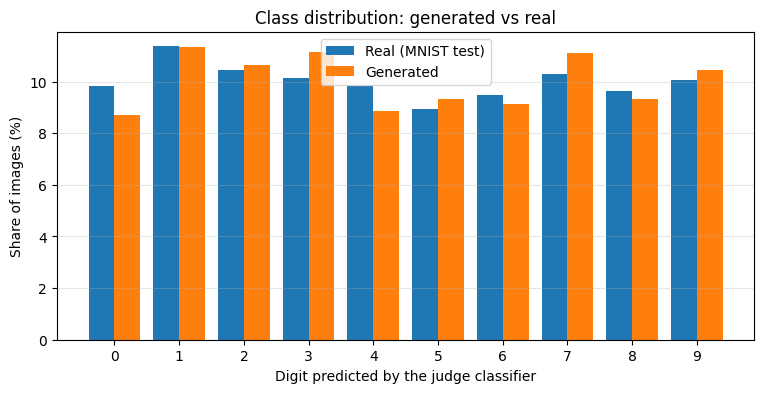

In [24]:
def judge_metrics(probs):
    conf = probs.max(1).values
    p_y = probs.mean(0)
    kl = (probs * (torch.log(probs + 1e-12) - torch.log(p_y + 1e-12))).sum(1)
    shares = torch.bincount(probs.argmax(1), minlength=10).float() / len(probs)
    entropy = -(shares * torch.log(shares + 1e-12)).sum() / math.log(10)
    return {
        "mean_confidence": round(conf.mean().item(), 4),
        "confident_share": round((conf >= 0.9).float().mean().item(), 4),
        "classifier_inception_score": round(torch.exp(kl.mean()).item(), 3),
        "class_entropy_normalized": round(entropy.item(), 4),
        "class_shares": [round(s, 4) for s in shares.tolist()],
    }

gen_probs = predict_probs(clf, gen_u8)
judge_gen = judge_metrics(gen_probs)
judge_real = judge_metrics(test_probs)

print(f"{'Mesure':<34}{'Générées':>10}{'Vraies (test)':>15}")
for k, label in [("mean_confidence", "Confiance moyenne"),
                 ("confident_share", "Part reconnue (confiance >= 0.9)"),
                 ("classifier_inception_score", "Inception Score (juge MNIST)"),
                 ("class_entropy_normalized", "Entropie des classes (max 1)")]:
    print(f"{label:<34}{judge_gen[k]:>10}{judge_real[k]:>15}")

x = np.arange(10)
plt.figure(figsize=(9, 4))
plt.bar(x - 0.2, 100 * np.array(judge_real["class_shares"]), width=0.4, label='Real (MNIST test)')
plt.bar(x + 0.2, 100 * np.array(judge_gen["class_shares"]), width=0.4, label='Generated')
plt.xticks(x)
plt.xlabel('Digit predicted by the judge classifier')
plt.ylabel('Share of images (%)')
plt.title('Class distribution: generated vs real')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.savefig(os.path.join(FIG_DIR, 'class_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()

## 3. Généralisation : test de mémorisation

### Objectif
Vérifier que le modèle **crée** de nouveaux chiffres au lieu de recopier des images d'entraînement.

### Explication
- Pour chaque image générée, on cherche l'image d'entraînement **la plus proche** (distance euclidienne sur les 784 pixels, valeurs dans [0, 1]).
- Pour savoir ce qu'est une distance « normale », on fait la même chose avec 5 000 **vraies images de test**, que le modèle n'a jamais vues.
- Si le modèle recopiait, ses images seraient beaucoup plus proches du jeu d'entraînement que les images de test.

### Mesure
On prend le seuil du 1 % des images de test les plus proches de l'entraînement. Sans mémorisation, environ **1 %** des images générées passent aussi sous ce seuil. Une part bien plus grande indiquerait des copies.

La figure montre les 8 images générées **les plus proches** de l'entraînement (le pire cas), à côté de leur plus proche voisin.

Distance médiane au plus proche voisin : générées 4.51 | test 4.38
Images générées sous le seuil du 1 % du test : 0.34 % (attendu ~1 % sans mémorisation)


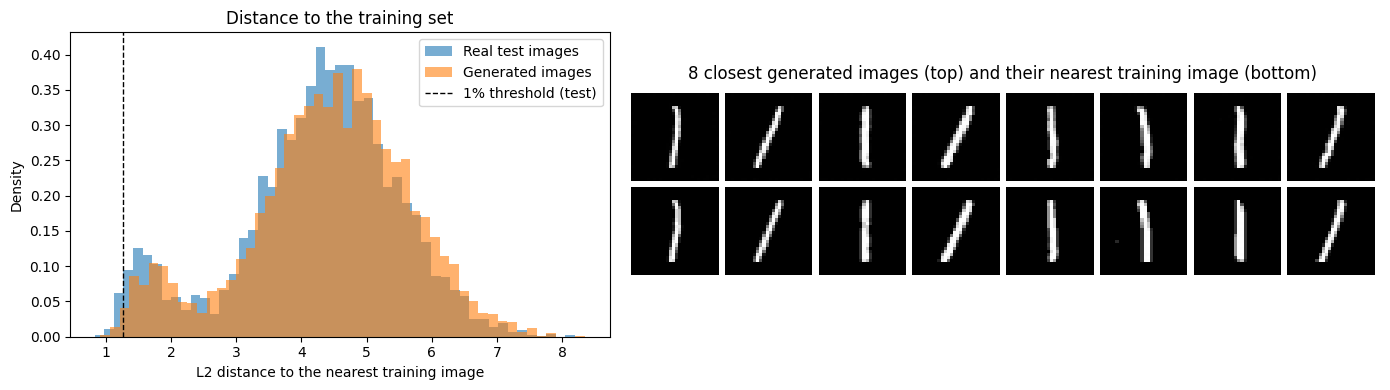

In [25]:
@torch.no_grad()
def nearest_train_neighbors(query_u8, ref_u8=train_u8, chunk=500):
    ref = (ref_u8.float() / 255).view(len(ref_u8), -1).to(device)
    dists, idxs = [], []
    for i in range(0, len(query_u8), chunk):
        q = (query_u8[i:i + chunk].float() / 255).view(-1, ref.shape[1]).to(device)
        d, j = torch.cdist(q, ref).min(dim=1)
        dists.append(d.cpu())
        idxs.append(j.cpu())
    return torch.cat(dists), torch.cat(idxs)

gen_nn_dist, gen_nn_idx = nearest_train_neighbors(gen_u8)
test_nn_dist, _ = nearest_train_neighbors(test_u8[:N_GEN])
threshold = torch.quantile(test_nn_dist, 0.01).item()
close_share = (gen_nn_dist < threshold).float().mean().item()

print(f"Distance médiane au plus proche voisin : générées {gen_nn_dist.median():.2f} | test {test_nn_dist.median():.2f}")
print(f"Images générées sous le seuil du 1 % du test : {100 * close_share:.2f} % (attendu ~1 % sans mémorisation)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].hist(test_nn_dist.numpy(), bins=50, alpha=0.6, density=True, label='Real test images')
axes[0].hist(gen_nn_dist.numpy(), bins=50, alpha=0.6, density=True, label='Generated images')
axes[0].axvline(threshold, color='k', ls='--', lw=1, label='1% threshold (test)')
axes[0].set_xlabel('L2 distance to the nearest training image')
axes[0].set_ylabel('Density')
axes[0].set_title('Distance to the training set')
axes[0].legend()

closest = torch.argsort(gen_nn_dist)[:8]
pairs = torch.cat([gen_u8[closest], train_u8[gen_nn_idx[closest]]])
axes[1].imshow(torchvision.utils.make_grid(pairs.float() / 255, nrow=8, padding=2, pad_value=1.0)[0], cmap='gray')
axes[1].set_title('8 closest generated images (top) and their nearest training image (bottom)')
axes[1].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'memorization_check.png'), dpi=150, bbox_inches='tight')
plt.show()

## Résumé et sauvegarde des résultats

### Objectif
Regrouper toutes les mesures dans `metrics.json` et télécharger les figures.

### Explication
Le fichier `ddpm_mnist_results.zip` contient `metrics.json`, `training_log.json` et toutes les figures.

In [26]:
metrics = {
    "model": {"n_params_M": log["n_params_M"], "timesteps": T, "schedule": schedule_name,
              "train_time_min": log.get("train_time_min"),
              "sec_per_epoch": log.get("sec_per_epoch"), "gpu": log.get("gpu"),
              "final_loss": round(log["losses"][-1], 4) if log.get("losses") else None},
    "generation": {"n_samples": len(gen_u8), "minutes": round(gen_seconds / 60, 1),
                   "ms_per_image": round(1000 * gen_seconds / len(gen_u8), 1)},
    "fid": {"generated_vs_test": round(fid_generated, 2), "real_train_vs_test_reference": round(fid_reference, 2),
            "n_generated": len(gen_u8), "n_test_reference": len(test_u8)},
    "judge_classifier": {"test_accuracy": round(clf_test_acc, 4), "generated": judge_gen, "real_test": judge_real},
    "memorization": {"median_nn_distance_generated": round(gen_nn_dist.median().item(), 3),
                     "median_nn_distance_test": round(test_nn_dist.median().item(), 3),
                     "share_below_test_1pct_threshold": round(close_share, 4)},
}
json.dump(metrics, open(os.path.join(WORK_DIR, 'metrics.json'), 'w'), indent=2)

print(f"FID                          : {fid_generated:.2f} (référence vraies images : {fid_reference:.2f})")
print(f"Chiffres reconnus (>= 0.9)    : {100 * judge_gen['confident_share']:.1f} % (vraies : {100 * judge_real['confident_share']:.1f} %)")
print(f"Inception Score (juge MNIST) : {judge_gen['classifier_inception_score']:.2f} (vraies : {judge_real['classifier_inception_score']:.2f}, max 10)")
print(f"Entropie des classes         : {judge_gen['class_entropy_normalized']:.3f} (vraies : {judge_real['class_entropy_normalized']:.3f})")
print(f"Proches de l'entraînement    : {100 * close_share:.2f} % (attendu ~1 %)")

import shutil
for name in ['metrics.json', 'training_log.json']:
    shutil.copy(os.path.join(WORK_DIR, name), FIG_DIR)
archive = shutil.make_archive('/content/ddpm_mnist_results' if WORK_DIR.startswith('/content') else 'ddpm_mnist_results', 'zip', FIG_DIR)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print("Archive :", archive)

FID                          : 3.60 (référence vraies images : 2.20)
Chiffres reconnus (>= 0.9)    : 88.2 % (vraies : 97.2 %)
Inception Score (juge MNIST) : 8.88 (vraies : 9.63, max 10)
Entropie des classes         : 0.998 (vraies : 0.999)
Proches de l'entraînement    : 0.34 % (attendu ~1 %)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>